# Notebook 10 — Diagnóstico por sujeito (PulseDB CalBased Test)

**Projeto de Iniciação Científica PIBIC — PUC-SP**
**Aluna:** Letícia Barboza de Godoi
**Orientador:** Prof. Dr. Renan Trevisoli Doria
**Curso:** Engenharia Biomédica

---

## Motivação

O Notebook 09 obteve, na validação externa do PulseDB CalBased Test, um MAE global de 15,71 mmHg (PAS) e 8,77 mmHg (PAD), com R² negativo para a pressão sistólica. Esses valores agregados, porém, **não revelam se o desempenho insatisfatório é uniforme entre os 1.293 sujeitos ou se decorre de um subconjunto de sujeitos com erro muito elevado** que distorce a média.

Este notebook investiga a **distribuição do erro por sujeito**, respondendo às seguintes perguntas:

1. O erro é homogêneo entre sujeitos, ou existem outliers que elevam a média global?
2. Que proporção de sujeitos atingiria, individualmente, os critérios BHS (Grau A/B/C)?
3. O que caracteriza os sujeitos com pior desempenho (faixa de PA, idade, número de ciclos)?
4. Qual seria o MAE da maioria dos sujeitos, excluindo os outliers?
5. O erro está associado à pressão arterial real do sujeito (indício de regressão à média)?

Este diagnóstico é puramente analítico: utiliza as predições já calculadas e persistidas pelo NB09, sem reprocessar sinais. Sua execução leva poucos segundos.

---


## 1. Importações e carregamento

In [1]:
import os
import socket
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["savefig.facecolor"] = "white"
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["figure.dpi"] = 100

print("Computador:", socket.gethostname())
print("Inicio:", datetime.now().strftime("%d/%m/%Y %H:%M:%S"))

Computador: NtebookLeticia
Inicio: 10/06/2026 18:58:40


In [2]:
BASE_IC = Path(r"C:\IC_PPG")
PASTA_PULSEDB_FEAT = BASE_IC / "Datasets" / "PulseDB_features"
PASTA_FIGS = BASE_IC / "Figuras_Geradas"

arquivo_csv = PASTA_PULSEDB_FEAT / "_features_pulsedb_calbased_test.csv"
if not arquivo_csv.exists():
    raise FileNotFoundError(f"CSV nao encontrado: {arquivo_csv}")

print(f"Carregando {arquivo_csv.name} (~344 MB, pode demorar 20-40s)...")
inicio = datetime.now()
df = pd.read_csv(arquivo_csv)
print(f"Carregado em {(datetime.now()-inicio).total_seconds():.1f} s")
print(f"Shape: {df.shape[0]} ciclos x {df.shape[1]} colunas")

Carregando _features_pulsedb_calbased_test.csv (~344 MB, pode demorar 20-40s)...
Carregado em 5.4 s
Shape: 573758 ciclos x 62 colunas


In [3]:
# Filtra apenas os ciclos de TESTE que foram efetivamente calibrados
# (split == "Test" e predicao calibrada nao-nula)
mask_teste = (df["split"] == "Test") & df["y_sys_pred_cal"].notna() & df["y_dia_pred_cal"].notna()
df_teste = df[mask_teste].copy().reset_index(drop=True)

print(f"Ciclos de teste calibrados: {len(df_teste)}")
print(f"Sujeitos: {df_teste['subject'].nunique()}")
print()

# Sanity check: reproduz o MAE global do NB09
mae_sys_global = mean_absolute_error(df_teste["bp_sys_mean"], df_teste["y_sys_pred_cal"])
mae_dia_global = mean_absolute_error(df_teste["bp_dia_mean"], df_teste["y_dia_pred_cal"])
print(f"MAE global PAS: {mae_sys_global:.2f} mmHg  (NB09 reportou 15.71)")
print(f"MAE global PAD: {mae_dia_global:.2f} mmHg  (NB09 reportou  8.77)")

Ciclos de teste calibrados: 503667
Sujeitos: 1293

MAE global PAS: 15.71 mmHg  (NB09 reportou 15.71)
MAE global PAD: 8.77 mmHg  (NB09 reportou  8.77)


## 2. Cálculo do MAE por sujeito

Para cada um dos 1.293 sujeitos, calcula-se o MAE individual (PAS e PAD), o número de ciclos de teste, a PA real média e a idade. Isso permite caracterizar a heterogeneidade do desempenho.


In [4]:
# Agrupa por sujeito e calcula metricas individuais
registros = []
for subj, grupo in df_teste.groupby("subject"):
    erro_sys = np.abs(grupo["bp_sys_mean"].values - grupo["y_sys_pred_cal"].values)
    erro_dia = np.abs(grupo["bp_dia_mean"].values - grupo["y_dia_pred_cal"].values)
    registros.append({
        "subject":      subj,
        "n_ciclos":     len(grupo),
        "mae_sys":      erro_sys.mean(),
        "mae_dia":      erro_dia.mean(),
        "pa_sys_real":  grupo["bp_sys_mean"].mean(),
        "pa_dia_real":  grupo["bp_dia_mean"].mean(),
        "idade":        grupo["age"].mean(),
        "imc_peso":     grupo["weight"].mean(),
        "altura":       grupo["height"].mean(),
    })

df_subj = pd.DataFrame(registros)
print(f"Sujeitos analisados: {len(df_subj)}")
print()
print("Estatisticas do MAE por sujeito (PAS):")
print(df_subj["mae_sys"].describe().round(2).to_string())
print()
print("Estatisticas do MAE por sujeito (PAD):")
print(df_subj["mae_dia"].describe().round(2).to_string())

Sujeitos analisados: 1293

Estatisticas do MAE por sujeito (PAS):
count    1293.00
mean       15.72
std         7.70
min         3.85
25%        10.29
50%        14.04
75%        19.09
max        71.71

Estatisticas do MAE por sujeito (PAD):
count    1293.00
mean        8.75
std         4.53
min         1.89
25%         5.57
50%         7.66
75%        10.80
max        47.49


## 3. Distribuição do MAE por sujeito

A figura abaixo mostra os histogramas do MAE individual. Se a distribuição for concentrada com cauda longa à direita, isso confirma a presença de outliers que elevam a média global.


Figura salva: diagnostico_mae_por_sujeito.png


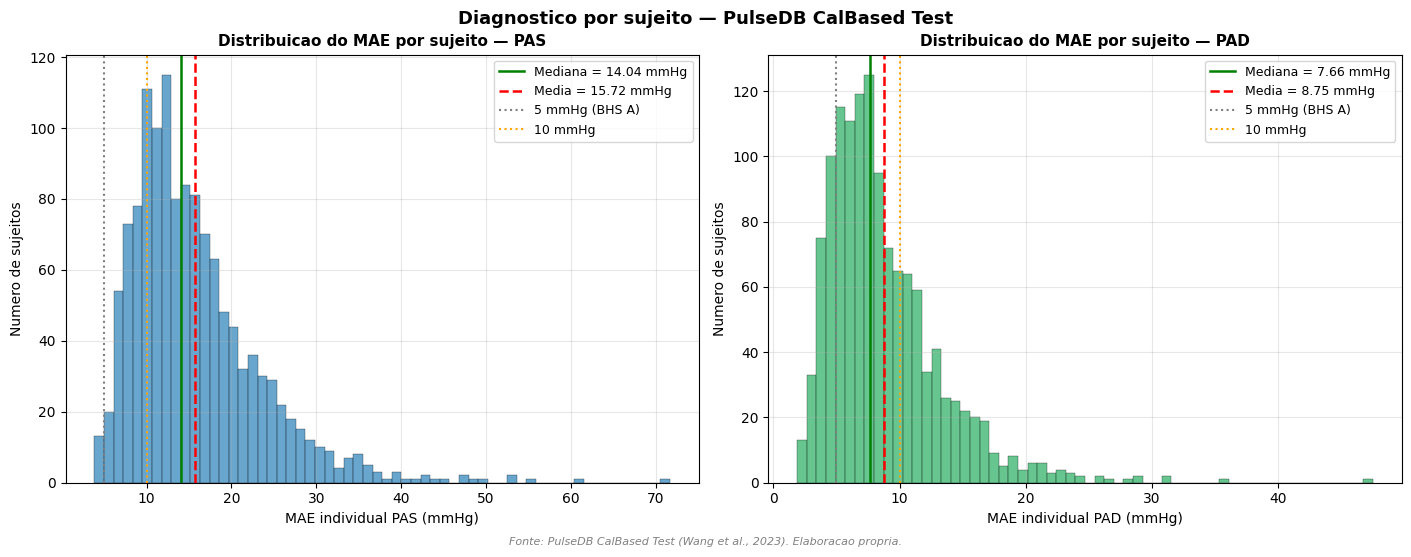

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

for ax, col, alvo, cor in [
    (axes[0], "mae_sys", "PAS", "#2980b9"),
    (axes[1], "mae_dia", "PAD", "#27ae60"),
]:
    valores = df_subj[col].values
    mediana = np.median(valores)
    media = np.mean(valores)

    ax.hist(valores, bins=60, color=cor, alpha=0.7, edgecolor="black", linewidth=0.3)
    ax.axvline(mediana, color="green", linestyle="-", linewidth=1.8,
               label=f"Mediana = {mediana:.2f} mmHg")
    ax.axvline(media, color="red", linestyle="--", linewidth=1.8,
               label=f"Media = {media:.2f} mmHg")
    ax.axvline(5, color="gray", linestyle=":", linewidth=1.5, label="5 mmHg (BHS A)")
    ax.axvline(10, color="orange", linestyle=":", linewidth=1.5, label="10 mmHg")

    ax.set_xlabel(f"MAE individual {alvo} (mmHg)", fontsize=10)
    ax.set_ylabel("Numero de sujeitos", fontsize=10)
    ax.set_title(f"Distribuicao do MAE por sujeito — {alvo}", fontsize=11, fontweight="bold")
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

fig.suptitle("Diagnostico por sujeito — PulseDB CalBased Test",
             fontsize=13, fontweight="bold", y=1.04)
fig.text(0.5, -0.03,
         "Fonte: PulseDB CalBased Test (Wang et al., 2023). Elaboracao propria.",
         ha="center", fontsize=8, style="italic", color="gray")

caminho_fig = PASTA_FIGS / "diagnostico_mae_por_sujeito.png"
plt.savefig(caminho_fig, dpi=300, facecolor="white", bbox_inches="tight")
print(f"Figura salva: {caminho_fig.name}")
plt.show()

## 4. Proporção de sujeitos por faixa de MAE

Quantifica quantos sujeitos atingiriam, individualmente, cada faixa de desempenho. Esta é a informação mais relevante para a narrativa do artigo: se a maioria dos sujeitos tem MAE baixo, o problema é localizado em outliers.


In [6]:
def proporcao_faixas(serie, faixas=[5, 10, 15, 20, 30]):
    total = len(serie)
    print(f"{'Faixa':<15} {'N sujeitos':>12} {'Percentual':>12}")
    print("-" * 42)
    for limite in faixas:
        n = (serie <= limite).sum()
        pct = 100 * n / total
        print(f"MAE <= {limite:>2} mmHg    {n:>12} {pct:>11.1f}%")

print("PAS — proporcao de sujeitos por faixa de MAE individual")
print("=" * 45)
proporcao_faixas(df_subj["mae_sys"])
print()
print("PAD — proporcao de sujeitos por faixa de MAE individual")
print("=" * 45)
proporcao_faixas(df_subj["mae_dia"])

PAS — proporcao de sujeitos por faixa de MAE individual
Faixa             N sujeitos   Percentual
------------------------------------------
MAE <=  5 mmHg              13         1.0%
MAE <= 10 mmHg             297        23.0%
MAE <= 15 mmHg             720        55.7%
MAE <= 20 mmHg            1002        77.5%
MAE <= 30 mmHg            1229        95.1%

PAD — proporcao de sujeitos por faixa de MAE individual
Faixa             N sujeitos   Percentual
------------------------------------------
MAE <=  5 mmHg             233        18.0%
MAE <= 10 mmHg             901        69.7%
MAE <= 15 mmHg            1178        91.1%
MAE <= 20 mmHg            1257        97.2%
MAE <= 30 mmHg            1289        99.7%


## 5. Caracterização dos sujeitos com pior desempenho

Os 20 sujeitos com maior MAE em PAS são examinados para identificar padrões: PA extrema, idade, número reduzido de ciclos, etc.


In [7]:
piores = df_subj.nlargest(20, "mae_sys")

print("20 SUJEITOS COM PIOR MAE EM PAS")
print("=" * 90)
print(piores[["subject", "n_ciclos", "mae_sys", "mae_dia",
              "pa_sys_real", "pa_dia_real", "idade"]].round(1).to_string(index=False))

print()
print("Comparacao: medianas dos 20 piores vs todos os sujeitos")
print("-" * 60)
for col, nome in [("pa_sys_real", "PA sistolica real"),
                  ("pa_dia_real", "PA diastolica real"),
                  ("idade", "Idade"),
                  ("n_ciclos", "Numero de ciclos")]:
    med_piores = piores[col].median()
    med_todos = df_subj[col].median()
    print(f"  {nome:<22} piores={med_piores:>7.1f}  |  todos={med_todos:>7.1f}")

20 SUJEITOS COM PIOR MAE EM PAS
   subject  n_ciclos  mae_sys  mae_dia  pa_sys_real  pa_dia_real  idade
vp005762_1       346     71.7     15.7        125.5         75.5   66.0
vp005802_1       393     61.0     31.5        148.9         78.9   74.0
vp005197_1       359     55.2     26.2        119.1         64.1   76.0
vp002793_1       360     52.8     22.1        110.9         66.1   60.0
vp001933_1       392     52.6     29.0        151.4         77.4   62.0
vp000787_1       542     49.8     26.7        102.6         60.3   66.0
vp005033_1       364     48.2     15.7        146.1         84.2   38.0
vp003518_1       332     47.4     28.2        122.8         63.5   75.0
vp000537_1       450     46.9     15.1        112.0         72.1   73.0
vp005741_1       377     44.9     11.9        134.3         63.0   67.0
vp005391_1       319     43.6     18.6        125.4         66.0   74.0
vp000232_1       482     43.1     20.0         97.2         47.8   71.0
vp004288_1       419     42.5   

## 6. MAE excluindo outliers

Recalcula-se o MAE global considerando apenas os sujeitos abaixo do percentil 90 de MAE, simulando o desempenho da maioria da população. Este valor representa o que o modelo alcança nos sujeitos "típicos".


In [8]:
for alvo, col_mae, col_pred in [("PAS", "mae_sys", "y_sys_pred_cal"),
                                ("PAD", "mae_dia", "y_dia_pred_cal")]:
    p90 = df_subj[col_mae].quantile(0.90)
    sujeitos_bons = df_subj[df_subj[col_mae] <= p90]["subject"].values

    mask_bons = df_teste["subject"].isin(sujeitos_bons)
    col_real = "bp_sys_mean" if alvo == "PAS" else "bp_dia_mean"
    mae_filtrado = mean_absolute_error(
        df_teste.loc[mask_bons, col_real],
        df_teste.loc[mask_bons, col_pred]
    )
    mae_global = mean_absolute_error(df_teste[col_real], df_teste[col_pred])

    print(f"{alvo}:")
    print(f"  MAE global (todos sujeitos):           {mae_global:.2f} mmHg")
    print(f"  MAE excluindo 10% piores sujeitos:     {mae_filtrado:.2f} mmHg")
    print(f"  Diferenca:                             {mae_global - mae_filtrado:.2f} mmHg")
    print()

PAS:
  MAE global (todos sujeitos):           15.71 mmHg
  MAE excluindo 10% piores sujeitos:     13.85 mmHg
  Diferenca:                             1.87 mmHg

PAD:
  MAE global (todos sujeitos):           8.77 mmHg
  MAE excluindo 10% piores sujeitos:     7.65 mmHg
  Diferenca:                             1.11 mmHg



## 7. Relação entre erro e pressão arterial real

Investiga-se a hipótese de **regressão à média**: o modelo tende a subestimar pressões altas e superestimar pressões baixas. Se confirmada, o erro estará correlacionado com o desvio da PA real em relação à média populacional — fenômeno conhecido na literatura (Aguet et al., 2021) e que a calibração por sujeito busca mitigar.


Figura salva: diagnostico_regressao_media.png


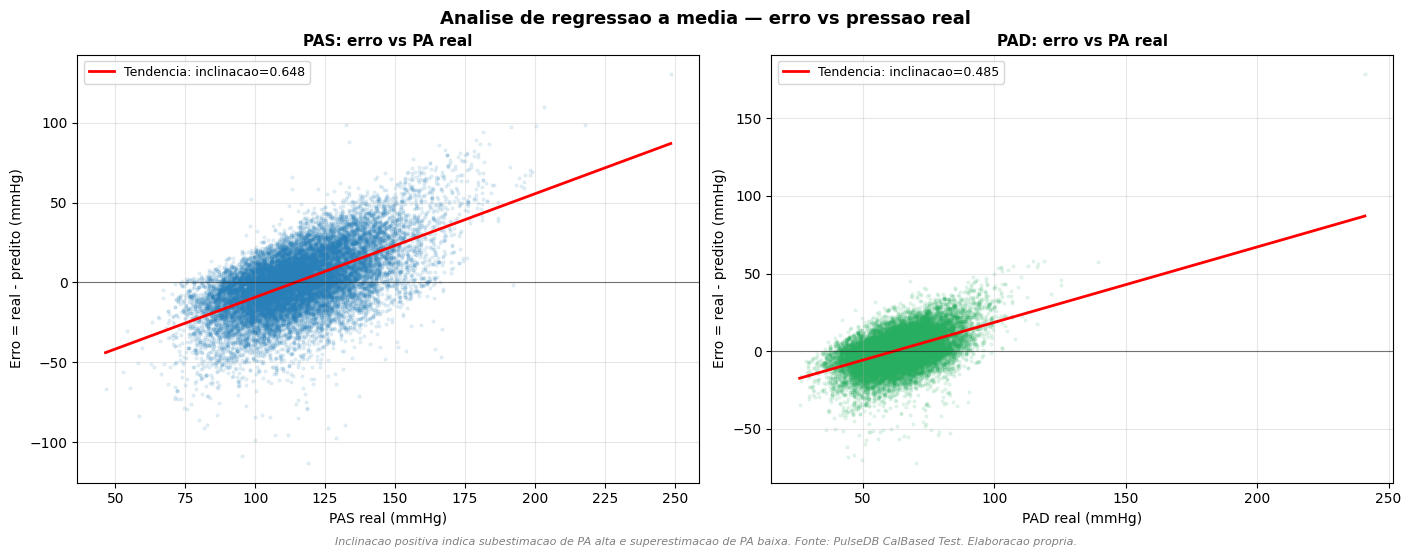

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

for ax, col_real, col_pred, alvo, cor in [
    (axes[0], "bp_sys_mean", "y_sys_pred_cal", "PAS", "#2980b9"),
    (axes[1], "bp_dia_mean", "y_dia_pred_cal", "PAD", "#27ae60"),
]:
    # Amostra para nao poluir o grafico (573k pontos eh demais)
    amostra = df_teste.sample(min(20000, len(df_teste)), random_state=42)
    pa_real = amostra[col_real].values
    erro = amostra[col_real].values - amostra[col_pred].values  # real - predito

    ax.scatter(pa_real, erro, alpha=0.1, s=4, color=cor)

    # Linha de tendencia
    coef = np.polyfit(pa_real, erro, 1)
    x_linha = np.linspace(pa_real.min(), pa_real.max(), 100)
    ax.plot(x_linha, np.polyval(coef, x_linha), color="red", linewidth=2,
            label=f"Tendencia: inclinacao={coef[0]:.3f}")

    ax.axhline(0, color="black", linestyle="-", linewidth=0.8, alpha=0.5)
    ax.set_xlabel(f"{alvo} real (mmHg)", fontsize=10)
    ax.set_ylabel(f"Erro = real - predito (mmHg)", fontsize=10)
    ax.set_title(f"{alvo}: erro vs PA real", fontsize=11, fontweight="bold")
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

fig.suptitle("Analise de regressao a media — erro vs pressao real",
             fontsize=13, fontweight="bold", y=1.04)
fig.text(0.5, -0.03,
         "Inclinacao positiva indica subestimacao de PA alta e superestimacao de PA baixa. "
         "Fonte: PulseDB CalBased Test. Elaboracao propria.",
         ha="center", fontsize=8, style="italic", color="gray")

caminho_fig = PASTA_FIGS / "diagnostico_regressao_media.png"
plt.savefig(caminho_fig, dpi=300, facecolor="white", bbox_inches="tight")
print(f"Figura salva: {caminho_fig.name}")
plt.show()

In [10]:
# Quantifica a regressao a media numericamente
print("QUANTIFICACAO DA REGRESSAO A MEDIA")
print("=" * 60)
for col_real, col_pred, alvo in [
    ("bp_sys_mean", "y_sys_pred_cal", "PAS"),
    ("bp_dia_mean", "y_dia_pred_cal", "PAD"),
]:
    pa_real = df_teste[col_real].values
    erro = pa_real - df_teste[col_pred].values
    coef = np.polyfit(pa_real, erro, 1)
    correl = np.corrcoef(pa_real, erro)[0, 1]
    print(f"\n{alvo}:")
    print(f"  Inclinacao (erro vs PA real): {coef[0]:.4f}")
    print(f"  Correlacao:                   {correl:.4f}")
    if coef[0] > 0.1:
        print(f"  -> REGRESSAO A MEDIA presente: subestima PA alta, superestima PA baixa")
    else:
        print(f"  -> Sem regressao a media forte")

QUANTIFICACAO DA REGRESSAO A MEDIA

PAS:
  Inclinacao (erro vs PA real): 0.6453
  Correlacao:                   0.5879
  -> REGRESSAO A MEDIA presente: subestima PA alta, superestima PA baixa

PAD:
  Inclinacao (erro vs PA real): 0.4749
  Correlacao:                   0.4904
  -> REGRESSAO A MEDIA presente: subestima PA alta, superestima PA baixa


## 8. Síntese do diagnóstico

Esta seção consolida os achados para orientar a decisão sobre os próximos passos (variar N de calibração e ciclo vale-a-vale).


In [11]:
print("SINTESE DO DIAGNOSTICO POR SUJEITO")
print("=" * 70)

# Recupera valores-chave
mediana_sys = df_subj["mae_sys"].median()
mediana_dia = df_subj["mae_dia"].median()
media_sys = df_subj["mae_sys"].mean()
media_dia = df_subj["mae_dia"].mean()
pct_sys_10 = 100 * (df_subj["mae_sys"] <= 10).mean()
pct_dia_10 = 100 * (df_subj["mae_dia"] <= 10).mean()

print(f"""
1. MEDIANA vs MEDIA do MAE por sujeito:
   PAS: mediana={mediana_sys:.2f} | media={media_sys:.2f} mmHg
   PAD: mediana={mediana_dia:.2f} | media={media_dia:.2f} mmHg
   (mediana << media indica outliers puxando a media para cima)

2. PROPORCAO de sujeitos com MAE <= 10 mmHg:
   PAS: {pct_sys_10:.1f}%
   PAD: {pct_dia_10:.1f}%

3. INTERPRETACAO:
   - Se a mediana for bem menor que a media -> outliers sao o problema
   - Se a maioria tiver MAE <= 10 -> o modelo funciona para a maior parte
   - A relacao erro vs PA real (Secao 7) indica se ha regressao a media residual
""")

print(f"Diagnostico concluido em: {datetime.now().strftime('%d/%m/%Y %H:%M:%S')}")

SINTESE DO DIAGNOSTICO POR SUJEITO

1. MEDIANA vs MEDIA do MAE por sujeito:
   PAS: mediana=14.04 | media=15.72 mmHg
   PAD: mediana=7.66 | media=8.75 mmHg
   (mediana << media indica outliers puxando a media para cima)

2. PROPORCAO de sujeitos com MAE <= 10 mmHg:
   PAS: 23.0%
   PAD: 69.7%

3. INTERPRETACAO:
   - Se a mediana for bem menor que a media -> outliers sao o problema
   - Se a maioria tiver MAE <= 10 -> o modelo funciona para a maior parte
   - A relacao erro vs PA real (Secao 7) indica se ha regressao a media residual

Diagnostico concluido em: 10/06/2026 18:58:51
